# Análisis exploratorio

**Objetivo:** entender la relación entre cada característica y el resultado del curso para decidir qué variables usar en los modelos y cómo plantear el problema.

| | |
|---|---|
| **Entrada** | `Datos/notas_pensamiento_cuantitativo.csv` |
| **Salidas** | `Datos/entrenamiento.csv`, `Datos/validacion.csv`, `Datos/prueba.csv` y las figuras de la carpeta [`figuras/`](figuras/) |
| **Siguiente paso** | [`../modelos/modelos.ipynb`](../modelos/modelos.ipynb) |

> **Decisión metodológica:** antes de explorar dividimos los datos en entrenamiento, validación y prueba, y **todo el análisis se hace únicamente con el conjunto de entrenamiento**. Así, la selección de variables no está influenciada por los datos con los que después se evalúan los modelos (se evita la fuga de información).

### Conclusiones principales
- La variable objetivo está **desbalanceada**: ~86 % aprueba y ~14 % reprueba. Por eso en el modelado se usan métricas centradas en la clase minoritaria (PR-AUC, F2) en lugar de la exactitud.
- Las variables con diferencias significativas entre aprobados y reprobados (Mann-Whitney, α = 0.05) son el PAA, el número de intento, el porcentaje acumulado en actividades y las notas de los parciales.
- **No** muestran diferencias significativas: las entregas tardías acumuladas (en ningún mes), la cantidad de comentarios y el delta de actividades en marzo y abril.
- Las puntuaciones z son redundantes con su versión original (VIF alto).
- Entre las variables categóricas, el colegio es la de mayor asociación con el resultado (V de Cramér = 0.30); el género tiene una asociación muy débil (V = 0.06).

In [ ]:
# Librerías
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import mannwhitneyu, chi2_contingency
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
import os
from scipy.stats import skew
from scipy.stats import mannwhitneyu, kruskal
os.makedirs("figuras", exist_ok=True)  # todas las figuras se guardan en figuras/

Diccionario de meses y lista de variables numéricas que se analizan.

In [2]:
# Nombres de los meses y variables numéricas a analizar
meses = {
    1: "Enero",
    2: "Febrero",
    3: "Marzo",
    4: "Abril",
    5: "Mayo"
}
variables =['PAA', 'NotaFinal', 'veces_curso', 'porcentaje_acum_actividades_mes_1',
       'porcentaje_acum_actividades_mes_2',
       'porcentaje_acum_actividades_mes_3',
       'porcentaje_acum_actividades_mes_4',
       'porcentaje_acum_actividades_mes_5', 'nota_examen_mes_2', 'nota_examen_mes_3', 'nota_examen_mes_4',
       'nota_examen_mes_5', 'delta_actividades_mes_2',
       'delta_actividades_mes_3', 'delta_actividades_mes_4',
       'delta_actividades_mes_5', 'z_porcentaje_acum_actividades_mes_1',
       'z_porcentaje_acum_actividades_mes_2',
       'z_porcentaje_acum_actividades_mes_3',
       'z_porcentaje_acum_actividades_mes_4',
       'z_porcentaje_acum_actividades_mes_5', 'z_nota_examen_mes_2',
       'z_nota_examen_mes_3', 'z_nota_examen_mes_4', 'z_nota_examen_mes_5', 'entregas_tarde_acum_mes_1', 'entregas_tarde_acum_mes_2',
       'entregas_tarde_acum_mes_3', 'entregas_tarde_acum_mes_4', 'entregas_tarde_acum_mes_5',
       'CantComentarios', 'DiferenciaPromedio']

Ahora vamos a analizar los datos para determinar qué modelo de aprendizaje automático debemos utilizar 

In [3]:
# Carga del dataset de modelado
datos = pd.read_csv('../../Datos/notas_pensamiento_cuantitativo.csv')

### División de los datos
**Decisión:** 70 % entrenamiento, 15 % validación y 15 % prueba, **estratificando por `Aprobado`** y con `random_state = 42` para que sea reproducible.

- Estratificamos porque la clase *reprobado* es minoritaria (~14 %); sin estratificar, los conjuntos de validación y prueba (349 estudiantes cada uno) podrían quedar con muy pocos reprobados.
- La validación se usa para elegir hiperparámetros y el umbral de decisión; la prueba se reserva para la evaluación final.

In [4]:
def dividir_datos(datos, estratificar=None, random_state=42):
    """Divide los datos en entrenamiento, validación y prueba (70/15/15) con estratificación opcional"""
    # estratificar: None, nombre de una columna, o un vector externo
    if estratificar is None:
        estratos = None
    elif isinstance(estratificar, str):
        estratos = datos[estratificar]
    else:
        estratos = np.asarray(estratificar)

    if estratos is None:
        train, temp = train_test_split(datos, test_size=0.30, random_state=random_state)
        val, test = train_test_split(temp, test_size=0.50, random_state=random_state)
    else:
        train, temp, _, est_temp = train_test_split(
            datos, estratos, test_size=0.30, random_state=random_state, stratify=estratos
        )
        val, test = train_test_split(
            temp, test_size=0.50, random_state=random_state, stratify=est_temp
        )

    return train, val, test

In [5]:
# División estratificada por Aprobado
train, val, test = dividir_datos(datos, estratificar="Aprobado")

In [6]:
# Exportación de los tres conjuntos
train.to_csv('../../Datos/entrenamiento.csv')
val.to_csv('../../Datos/validacion.csv')
test.to_csv('../../Datos/prueba.csv')

In [7]:
# El análisis se hace solo con el conjunto de entrenamiento
datos = train.copy()

In [8]:
# Dimensiones de entrenamiento
datos.shape

(1627, 41)

## Análisis de la variable objetivo

Primero, vamos a analizar las variables de interés, en este caso la variable binaria: **Aprobado** y la variable continua **NotaFinal**

In [9]:
# Distribución de la variable objetivo
datos["Aprobado"].value_counts()

Aprobado
1    1407
0     220
Name: count, dtype: int64

In [10]:
# Proporción de aprobados y reprobados
datos["Aprobado"].value_counts(normalize=True).round(2)

Aprobado
1    0.86
0    0.14
Name: proportion, dtype: float64

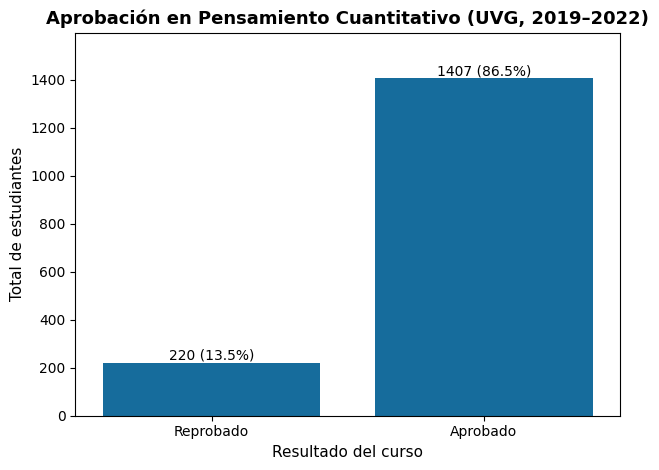

In [11]:
# Gráfica de aprobados y reprobados
total = len(datos)

ax = sns.countplot(
    data=datos,
    x="Aprobado",
    color="#0072B2",
    order=[0, 1]
)

ax.set_xticklabels(["Reprobado", "Aprobado"])
ax.set_title("Aprobación en Pensamiento Cuantitativo (UVG, 2019–2022)", fontsize=13, fontweight="bold")
ax.set_ylabel("Total de estudiantes", fontsize=11)
ax.set_xlabel("Resultado del curso", fontsize=11)

# Agregar etiquetas de conteo (%) encima de cada barra
for p in ax.patches:
    count = int(p.get_height())
    pct = count / total * 100
    ax.annotate(f"{count} ({pct:.1f}%)",
                (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontsize=10)

# Un poco de espacio extra arriba para que no se corte la etiqueta
ax.set_ylim(0, ax.get_ylim()[1] * 1.08)

plt.tight_layout()
plt.savefig("figuras/distribucion_aprobado.png", dpi=200, bbox_inches="tight")
plt.show()

Observamos que la variable binaria está desbalanceada, aproximadamente el 86% de los estudiantes aprobaron, mientras que solamente el 14% reprobó. 

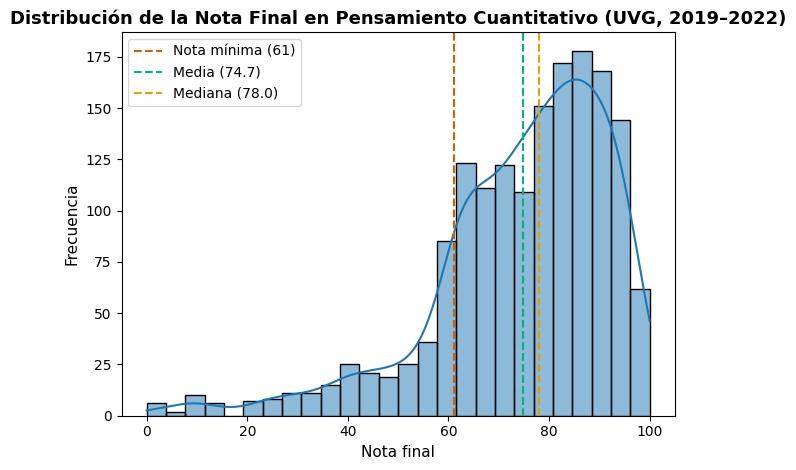

In [12]:
# Distribución de la nota final con la nota mínima, la media y la mediana
media = datos["NotaFinal"].mean()
mediana = datos["NotaFinal"].median()

sns.histplot(datos["NotaFinal"], kde=True)
plt.axvline(x=61, color="#D55E00", linestyle="--", label="Nota mínima (61)")
plt.axvline(x=media, color="#00B27D", linestyle="--", label=f"Media ({media:.1f})")
plt.axvline(x=mediana, color="#E69F00", linestyle="--", label=f"Mediana ({mediana:.1f})")

plt.title("Distribución de la Nota Final en Pensamiento Cuantitativo (UVG, 2019–2022)", fontsize=13, fontweight="bold")
plt.xlabel("Nota final", fontsize=11)
plt.ylabel("Frecuencia", fontsize=11)

plt.legend()
plt.tight_layout()
plt.savefig("figuras/distribucion_notafinal.png", dpi=200, bbox_inches="tight")
plt.show()

In [ ]:
# Coeficiente de asimetría de la nota final

sesgo = skew(datos["NotaFinal"])
print(f"Coeficiente de asimetría: {sesgo:.3f}")

Coeficiente de asimetría: -1.340


La variable numérica también sufre de un desbalance: la mayor parte de los estudiantes termina con una nota mayor o igual a 61. El coeficiente de asimetría (−1.34) confirma que la distribución tiene una cola larga hacia las notas bajas. Un detalle interesante es que la mayoría de estudiantes que reprueba tiene una nota cercana a 61.

In [14]:
# Estadísticas descriptivas de las variables numéricas
datos[['PAA', 'NotaFinal', 'veces_curso', 'porcentaje_acum_actividades_mes_1',
       'porcentaje_acum_actividades_mes_2',
       'porcentaje_acum_actividades_mes_3',
       'porcentaje_acum_actividades_mes_4',
       'porcentaje_acum_actividades_mes_5', 'nota_examen_mes_2', 'nota_examen_mes_3', 'nota_examen_mes_4',
       'nota_examen_mes_5', 'delta_actividades_mes_2',
       'delta_actividades_mes_3', 'delta_actividades_mes_4',
       'delta_actividades_mes_5', 'z_porcentaje_acum_actividades_mes_1',
       'z_porcentaje_acum_actividades_mes_2',
       'z_porcentaje_acum_actividades_mes_3',
       'z_porcentaje_acum_actividades_mes_4',
       'z_porcentaje_acum_actividades_mes_5', 'z_nota_examen_mes_2',
       'z_nota_examen_mes_3', 'z_nota_examen_mes_4', 'z_nota_examen_mes_5', 'entregas_tarde_acum_mes_1', 'entregas_tarde_acum_mes_2',
       'entregas_tarde_acum_mes_3', 'entregas_tarde_acum_mes_4', 'entregas_tarde_acum_mes_5',
       'CantComentarios', 'DiferenciaPromedio']].describe()

,PAA,NotaFinal,veces_curso,porcentaje_acum_actividades_mes_1,porcentaje_acum_actividades_mes_2,porcentaje_acum_actividades_mes_3,porcentaje_acum_actividades_mes_4,porcentaje_acum_actividades_mes_5,nota_examen_mes_2,nota_examen_mes_3,...,z_nota_examen_mes_3,z_nota_examen_mes_4,z_nota_examen_mes_5,entregas_tarde_acum_mes_1,entregas_tarde_acum_mes_2,entregas_tarde_acum_mes_3,entregas_tarde_acum_mes_4,entregas_tarde_acum_mes_5,CantComentarios,DiferenciaPromedio
count,1627.000000,1627.000000,1627.000000,1627.000000,1627.000000,1627.000000,1627.000000,1627.000000,1627.000000,1627.000000,...,1627.000000,1627.000000,1627.000000,1627.000000,1627.000000,1627.000000,1627.000000,1627.000000,1627.000000,1627.000000
mean,1244.357714,74.734481,1.114935,84.180324,79.353630,78.256121,79.218645,78.666214,71.552008,71.176608,...,-0.008137,0.004296,0.001586,0.506454,0.842041,0.957591,1.742471,2.301782,6.143208,7.481868
std,129.554834,17.668140,0.369091,17.555560,16.440121,16.796006,16.540877,16.628841,23.018164,22.714707,...,0.977534,0.968298,0.965827,0.915455,1.452487,1.479269,2.071462,2.895985,7.081829,2.756878
min,715.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,-4.379130,-4.246154,-3.919754,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,1160.000000,65.000000,1.000000,78.637349,72.206897,70.286437,72.156279,71.920273,58.000000,59.000000,...,-0.627371,-0.546885,-0.566627,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000
50%,1234.000000,78.000000,1.000000,89.933333,83.352941,82.281690,83.250000,82.508182,77.000000,76.000000,...,0.193815,0.225337,0.150472,0.000000,0.000000,0.000000,1.000000,1.000000,3.000000,7.000000
75%,1332.000000,88.000000,1.000000,95.636364,91.092653,90.238019,90.587379,90.033909,90.000000,89.000000,...,0.746012,0.724376,0.698753,1.000000,1.000000,1.000000,2.000000,3.000000,10.000000,8.000000
max,1583.000000,100.000000,4.000000,100.000000,100.000000,100.000000,100.000000,99.713636,100.000000,100.000000,...,2.074506,1.911448,2.357145,4.000000,7.000000,7.000000,10.000000,14.000000,60.000000,18.500000


Ahora analizamos con estadísticas descriptivas cada variable numérica:

- **PAA:** media de 1,244 y mediana de 1,234 puntos; el 75 % de los estudiantes supera los 1,160 puntos. Ningún estudiante registrado obtuvo la nota máxima (1,600 puntos); el máximo es 1,583.
- **NotaFinal:** media de 74.7 y mediana de 78; al menos el 75 % obtiene 65 puntos o más.
- **veces_curso:** la gran mayoría lleva el curso por primera vez (media de 1.11); es raro observar estudiantes que lo hayan cursado más veces (máximo 4).
- **Porcentaje acumulado en actividades:** es alto en enero (mediana ≈ 90 %) y baja ligeramente en los meses siguientes (mediana ≈ 82–83 %).
- **Notas de parciales:** medianas de 76–77 puntos en febrero y marzo, con mucha dispersión (desviación estándar ≈ 23).
- **Entregas tardías acumuladas:** la mayoría de estudiantes tiene pocas (mediana de 0 a 1 según el mes).
- **Velocidad de calificación:** mediana de 7 días entre la entrega y la calificación.

Nombres legibles para los títulos de gráficas y tablas.

In [15]:
# Nombres legibles para las gráficas
nombres_amigables = {
    'PAA': 'Puntaje PAA',
    'veces_curso': 'Veces que ha cursado la materia',
    'CantComentarios': 'Cantidad de comentarios',
    'DiferenciaPromedio': 'Velocidad de calificación',
    'NotaFinal': 'Nota Final',
}

for m in range(1, 6):
    nombres_amigables.update({
        f'porcentaje_acum_actividades_mes_{m}': f'Puntos acumulado en actividades en el mes de {meses[m]}',
        f'z_porcentaje_acum_actividades_mes_{m}': f'Puntuación Z en el porcentaje acumulado en actividades en el mes de {meses[m]}',
        f'entregas_tarde_acum_mes_{m}': f'Entregas tardías acumuladas hasta el mes de {meses[m]}',
    })

for m in range(2, 6):
    nombres_amigables.update({
        f'nota_examen_mes_{m}': f'Rendimiento en el examen parcial de {meses[m]}',
        f'z_nota_examen_mes_{m}': f'Puntuación Z en las notas de exámenes parciales en el mes de {m}',
        f'delta_actividades_mes_{m}': f'Cambio en el porcentaje acumulado en actividades - {meses[m]}',
    })

Funciones auxiliares para las gráficas y la prueba estadística.

**Decisión:** para comparar aprobados y reprobados usamos la **prueba U de Mann-Whitney** en lugar de la prueba *t*, porque es no paramétrica: no supone normalidad (varias variables están muy sesgadas, como se ve en los histogramas más abajo) y funciona bien con grupos de tamaños muy distintos (1,407 aprobados vs. 220 reprobados).

In [16]:
# Funciones auxiliares para gráficas
def formato_p(p_valor):
    """Da formato al p-valor con su nivel de significancia"""
    if p_valor < 0.001:
        return "p < 0.001 ***"
    elif p_valor < 0.01:
        return f"p = {p_valor:.4f} **"
    elif p_valor < 0.05:
        return f"p = {p_valor:.4f} *"
    return f"p = {p_valor:.4f} (ns)"


import textwrap

def graficar_boxplots(datos, variables, titulo, nombres=None, n_cols=3,
                      color="#0072B2", archivo=None, col_objetivo="Aprobado",
                      sharey=False, linea_ref=None, ancho_titulo=40,
                      etiquetas=("Reprobado", "Aprobado")):
    """Grafica boxplots de varias variables según una variable binaria y guarda la figura"""
    nombres = nombres or {}
    n_cols = min(n_cols, len(variables))
    n_rows = int(np.ceil(len(variables) / n_cols))

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5.3 * n_cols, 4.2 * n_rows),
                             sharey=sharey)
    axes = np.atleast_1d(axes).flatten()

    for ax, var in zip(axes, variables):
        sns.boxplot(x=col_objetivo, y=var, data=datos, color=color, order=[0, 1], ax=ax)
        ax.set_xticks([0, 1])
        ax.set_xticklabels(list(etiquetas))
        ax.set_xlabel("")
        ax.set_ylabel("")
        if linea_ref is not None:
            ax.axhline(linea_ref, color="gray", linestyle="--", linewidth=1)

        titulo_panel = textwrap.fill(nombres.get(var, var), width=ancho_titulo)
        ax.set_title(titulo_panel, fontsize=10.5, fontweight="bold")

    for ax in axes[len(variables):]:
        fig.delaxes(ax)

    fig.suptitle(titulo, fontsize=15, fontweight="bold", y=1.01)
    plt.tight_layout()
    if archivo:
        plt.savefig(archivo, dpi=200, bbox_inches="tight")
    plt.show()
    return fig

In [17]:
def prueba_mann_whitney(datos, var, nombres=None, col_objetivo="Aprobado"):
    """Aplica la prueba U de Mann-Whitney entre los dos grupos para una variable"""
    nombres = nombres or {}
    x0 = datos.loc[datos[col_objetivo] == 0, var].dropna()
    x1 = datos.loc[datos[col_objetivo] == 1, var].dropna()
    n0, n1 = len(x0), len(x1)

    if n0 > 0 and n1 > 0:
        u, p = mannwhitneyu(x0, x1, alternative="two-sided")
        r_rb = 1 - 2 * u / (n0 * n1)
    else:
        u = p = r_rb = np.nan

    if pd.isna(p):
        sig = ""
    elif p < 0.05:
        sig = "Paso la prueba"
    else:
        sig = "No paso la prueba"

    return {
        "Variable": nombres.get(var, var),
        "p_valor": p,
        "sig": sig,
        "Valor esperado": 0.05
    }

## Variables numéricas según el resultado del curso

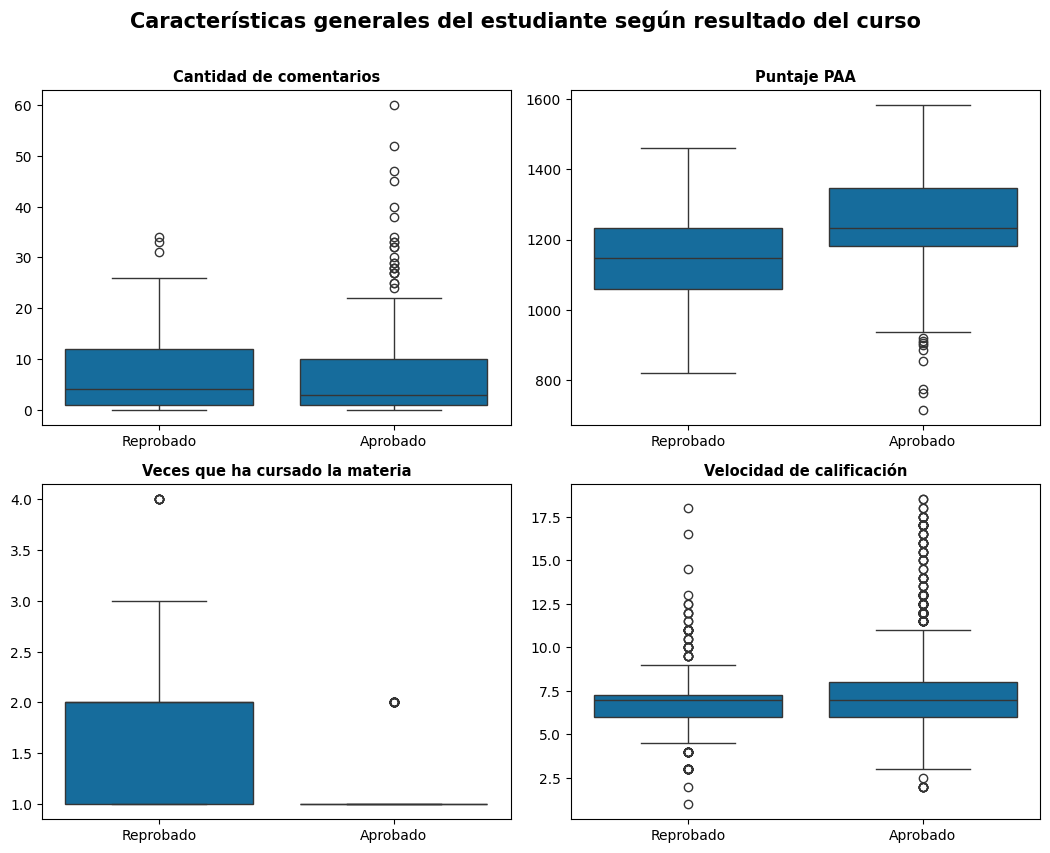

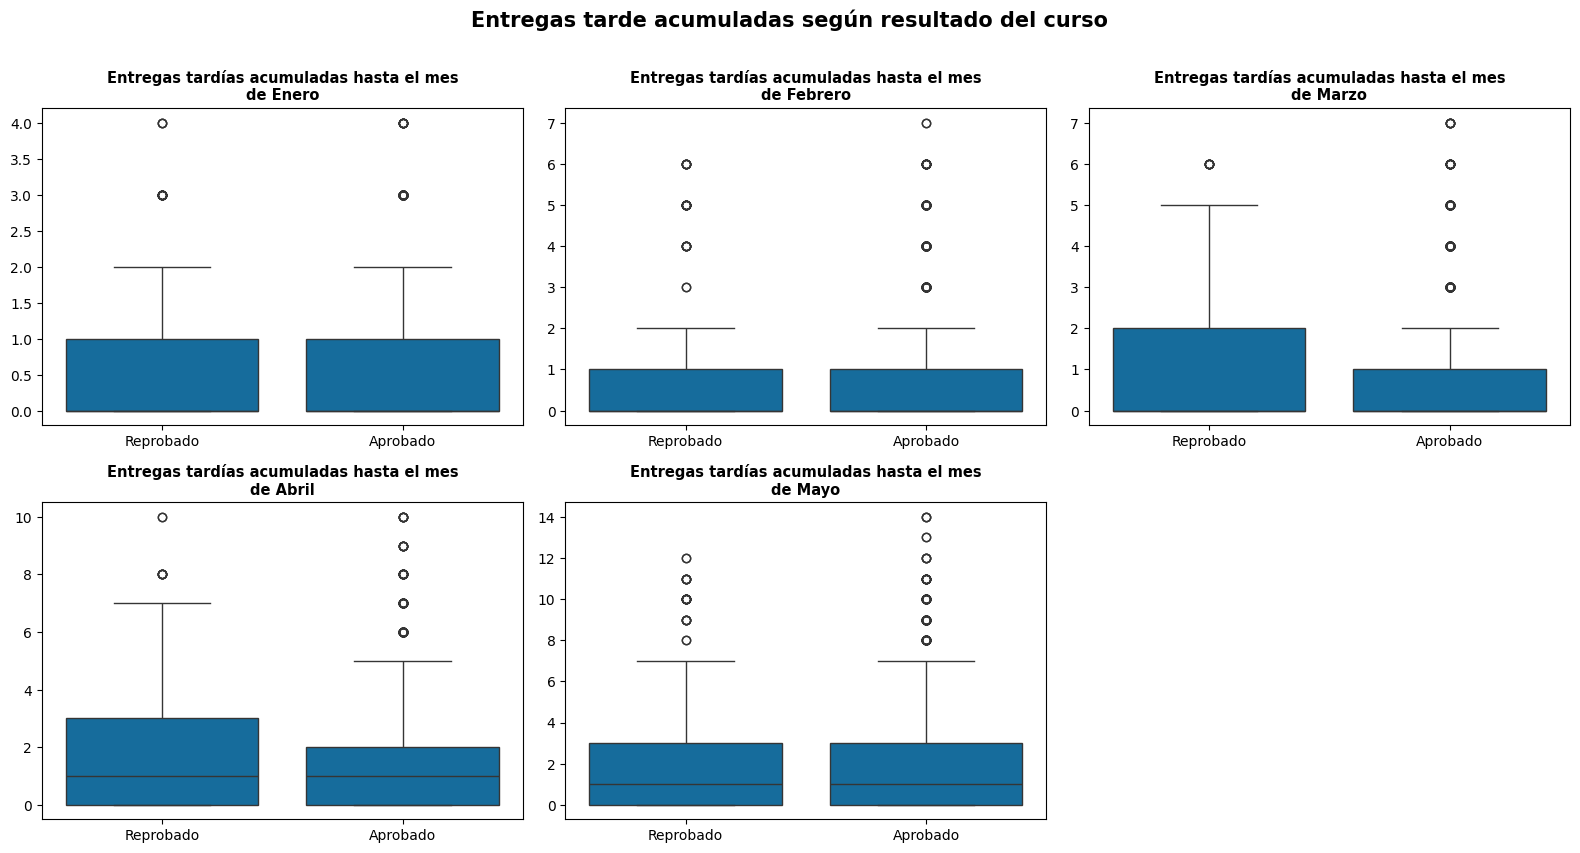

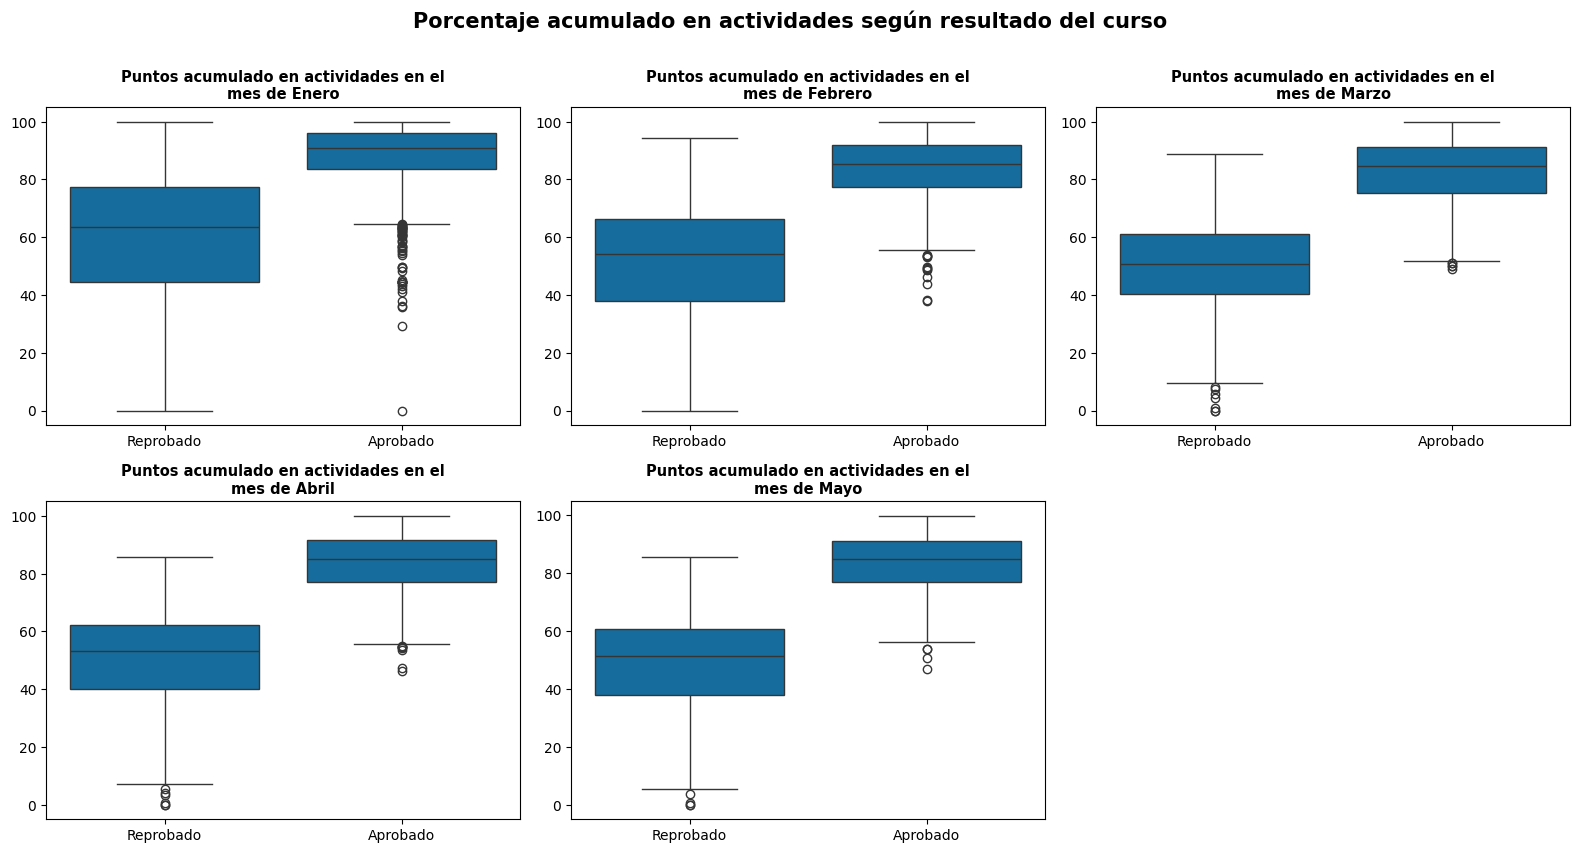

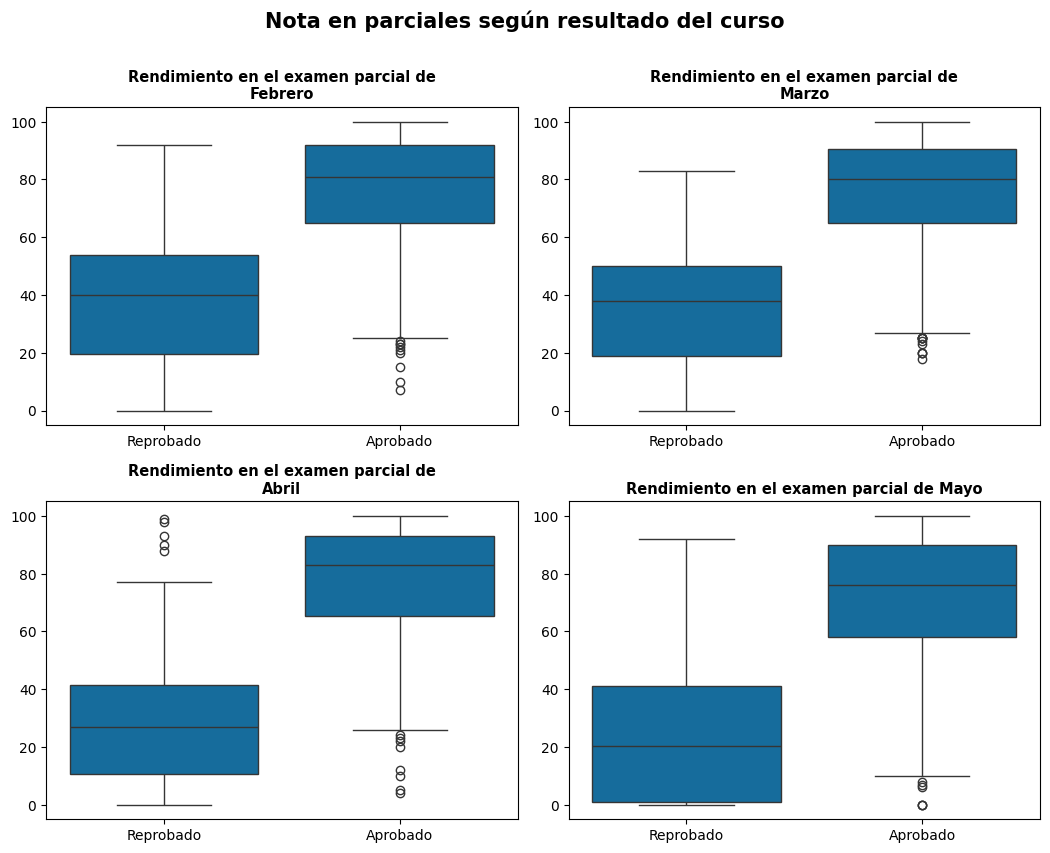

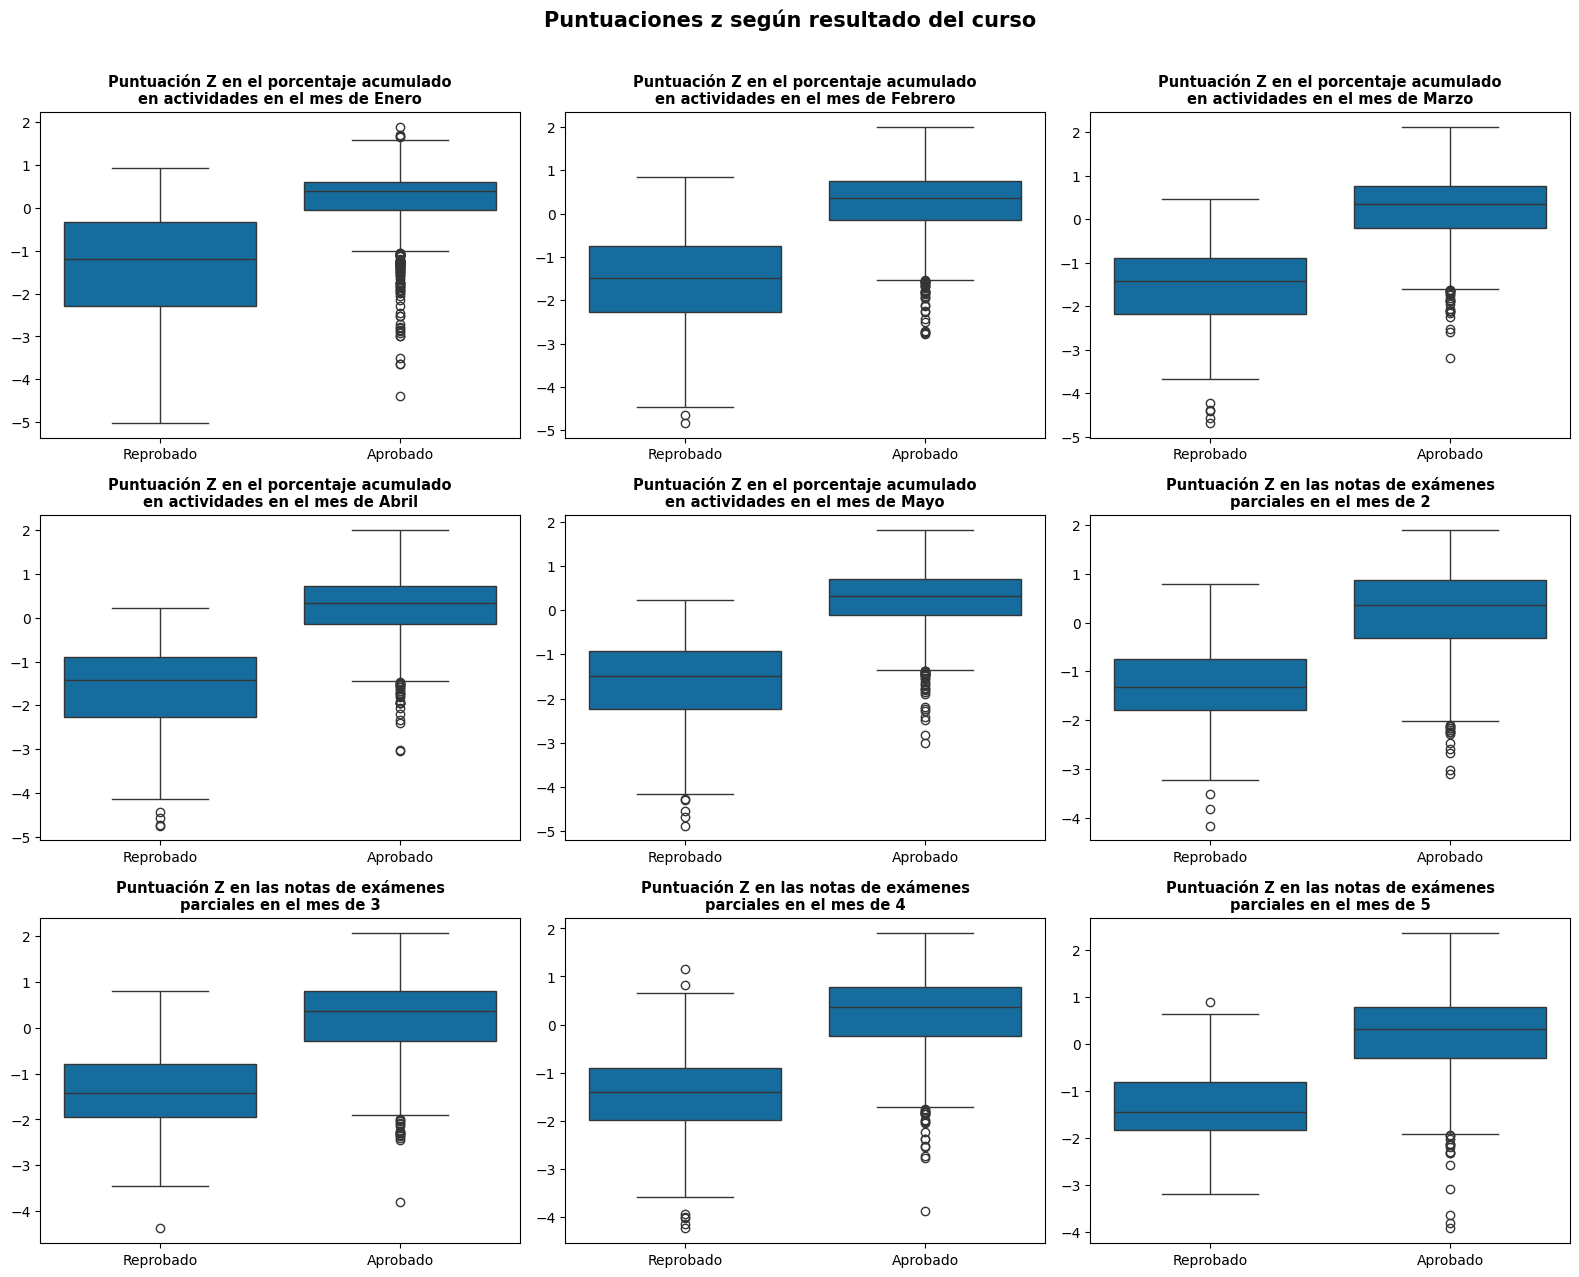

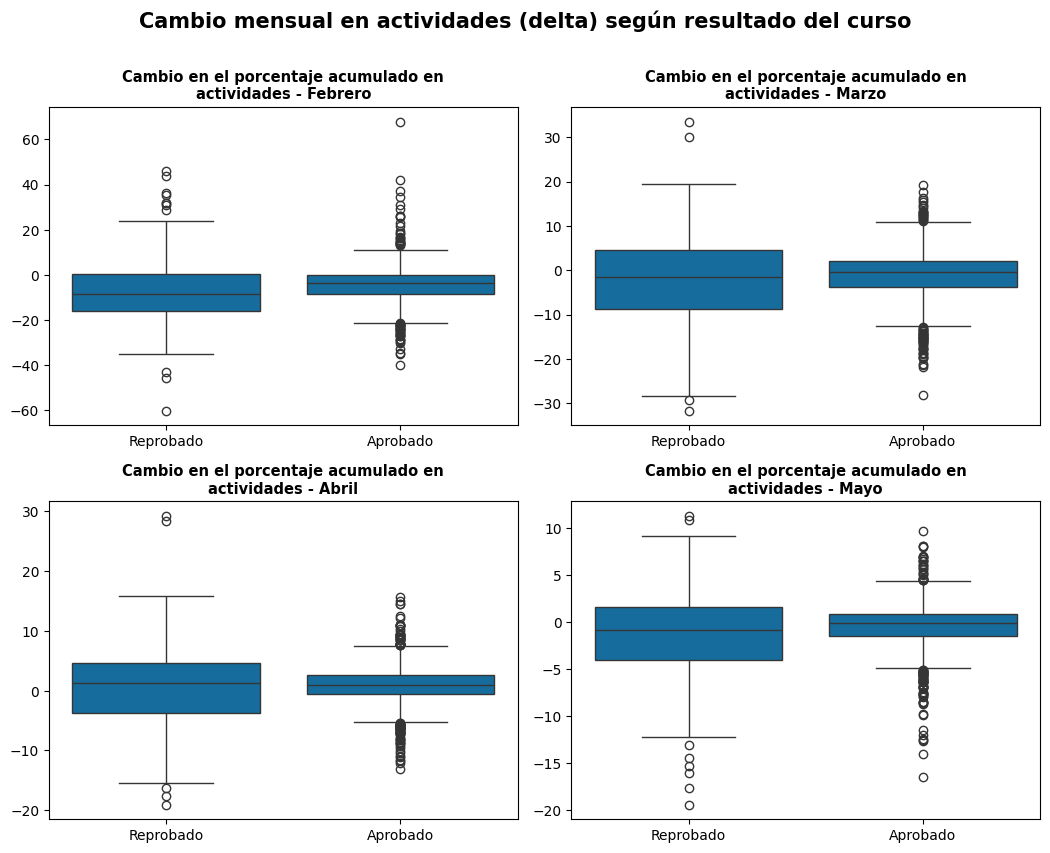

In [18]:
# Boxplots de las variables numéricas según el resultado del curso
meses_examen = range(2, 6)

# 1. Variables generales
graficar_boxplots(
    datos, ['CantComentarios', 'PAA', 'veces_curso', 'DiferenciaPromedio'],
    "Características generales del estudiante según resultado del curso",
    nombres=nombres_amigables, n_cols=2, archivo="figuras/boxplots_generales.png"
)

# 2. Entregas tarde
graficar_boxplots(
    datos, [f'entregas_tarde_acum_mes_{m}' for m in meses],
    "Entregas tarde acumuladas según resultado del curso",
    nombres=nombres_amigables, archivo="figuras/boxplots_entregas_tarde.png"
)

# 3. Puntos acumulados en actividades
graficar_boxplots(
    datos, [f'porcentaje_acum_actividades_mes_{m}' for m in meses],
    "Porcentaje acumulado en actividades según resultado del curso",
    nombres=nombres_amigables, archivo="figuras/boxplots_actividades.png"
)

# 4. Notas en parciales
graficar_boxplots(
    datos, [f'nota_examen_mes_{m}' for m in meses_examen],
    "Nota en parciales según resultado del curso",
    nombres=nombres_amigables, n_cols=2, archivo="figuras/boxplots_parciales.png"
)

# 5. Z-scores (actividades y parciales)
graficar_boxplots(
    datos,
    [f'z_porcentaje_acum_actividades_mes_{m}' for m in meses]
    + [f'z_nota_examen_mes_{m}' for m in meses_examen],
    "Puntuaciones z según resultado del curso",
    nombres=nombres_amigables, archivo="figuras/boxplots_zscore.png"
)

# 6. Deltas entre meses
graficar_boxplots(
    datos, [f'delta_actividades_mes_{m}' for m in meses_examen],
    "Cambio mensual en actividades (delta) según resultado del curso",
    nombres=nombres_amigables, n_cols=2, archivo="figuras/boxplots_delta.png"
);

Aplicamos Mann-Whitney a cada variable. H₀: la distribución de la variable es la misma en aprobados y reprobados; se rechaza si p < 0.05 ("Paso la prueba").

In [19]:
# Prueba de Mann-Whitney para cada variable
mann_u = pd.DataFrame([prueba_mann_whitney(datos, v, nombres_amigables) for v in variables])

In [20]:
# Resultados de la prueba
mann_u

,Variable,p_valor,sig,Valor esperado
0,Puntaje PAA,8.576992e-27,Paso la prueba,0.05
1,Nota Final,3.946545e-126,Paso la prueba,0.05
2,Veces que ha cursado la materia,9.645236e-178,Paso la prueba,0.05
3,Puntos acumulado en actividades en el mes de E...,2.941571e-64,Paso la prueba,0.05
4,Puntos acumulado en actividades en el mes de F...,1.814787e-97,Paso la prueba,0.05
5,Puntos acumulado en actividades en el mes de M...,1.210369e-99,Paso la prueba,0.05
6,Puntos acumulado en actividades en el mes de A...,4.370802e-105,Paso la prueba,0.05
7,Puntos acumulado en actividades en el mes de Mayo,1.266506e-106,Paso la prueba,0.05
8,Rendimiento en el examen parcial de Febrero,3.129926e-85,Paso la prueba,0.05
9,Rendimiento en el examen parcial de Marzo,4.874736e-93,Paso la prueba,0.05


**Resultados:**
- **Diferencias significativas:** PAA, número de intento, porcentaje acumulado en actividades (todos los meses), notas de parciales (todos los meses) y sus puntuaciones z.
- **Sin diferencias significativas:** entregas tardías acumuladas (p > 0.3 en todos los meses), cantidad de comentarios (p = 0.33) y delta de actividades en marzo y abril (en febrero y mayo sí lo es; el resultado es inconsistente).
- **Velocidad de calificación:** apenas significativa (p = 0.049).

Estas conclusiones guían la selección de variables: las entregas tardías, los comentarios, los deltas y la velocidad de calificación no se usan en los modelos.

A continuación, la distribución de cada variable numérica.

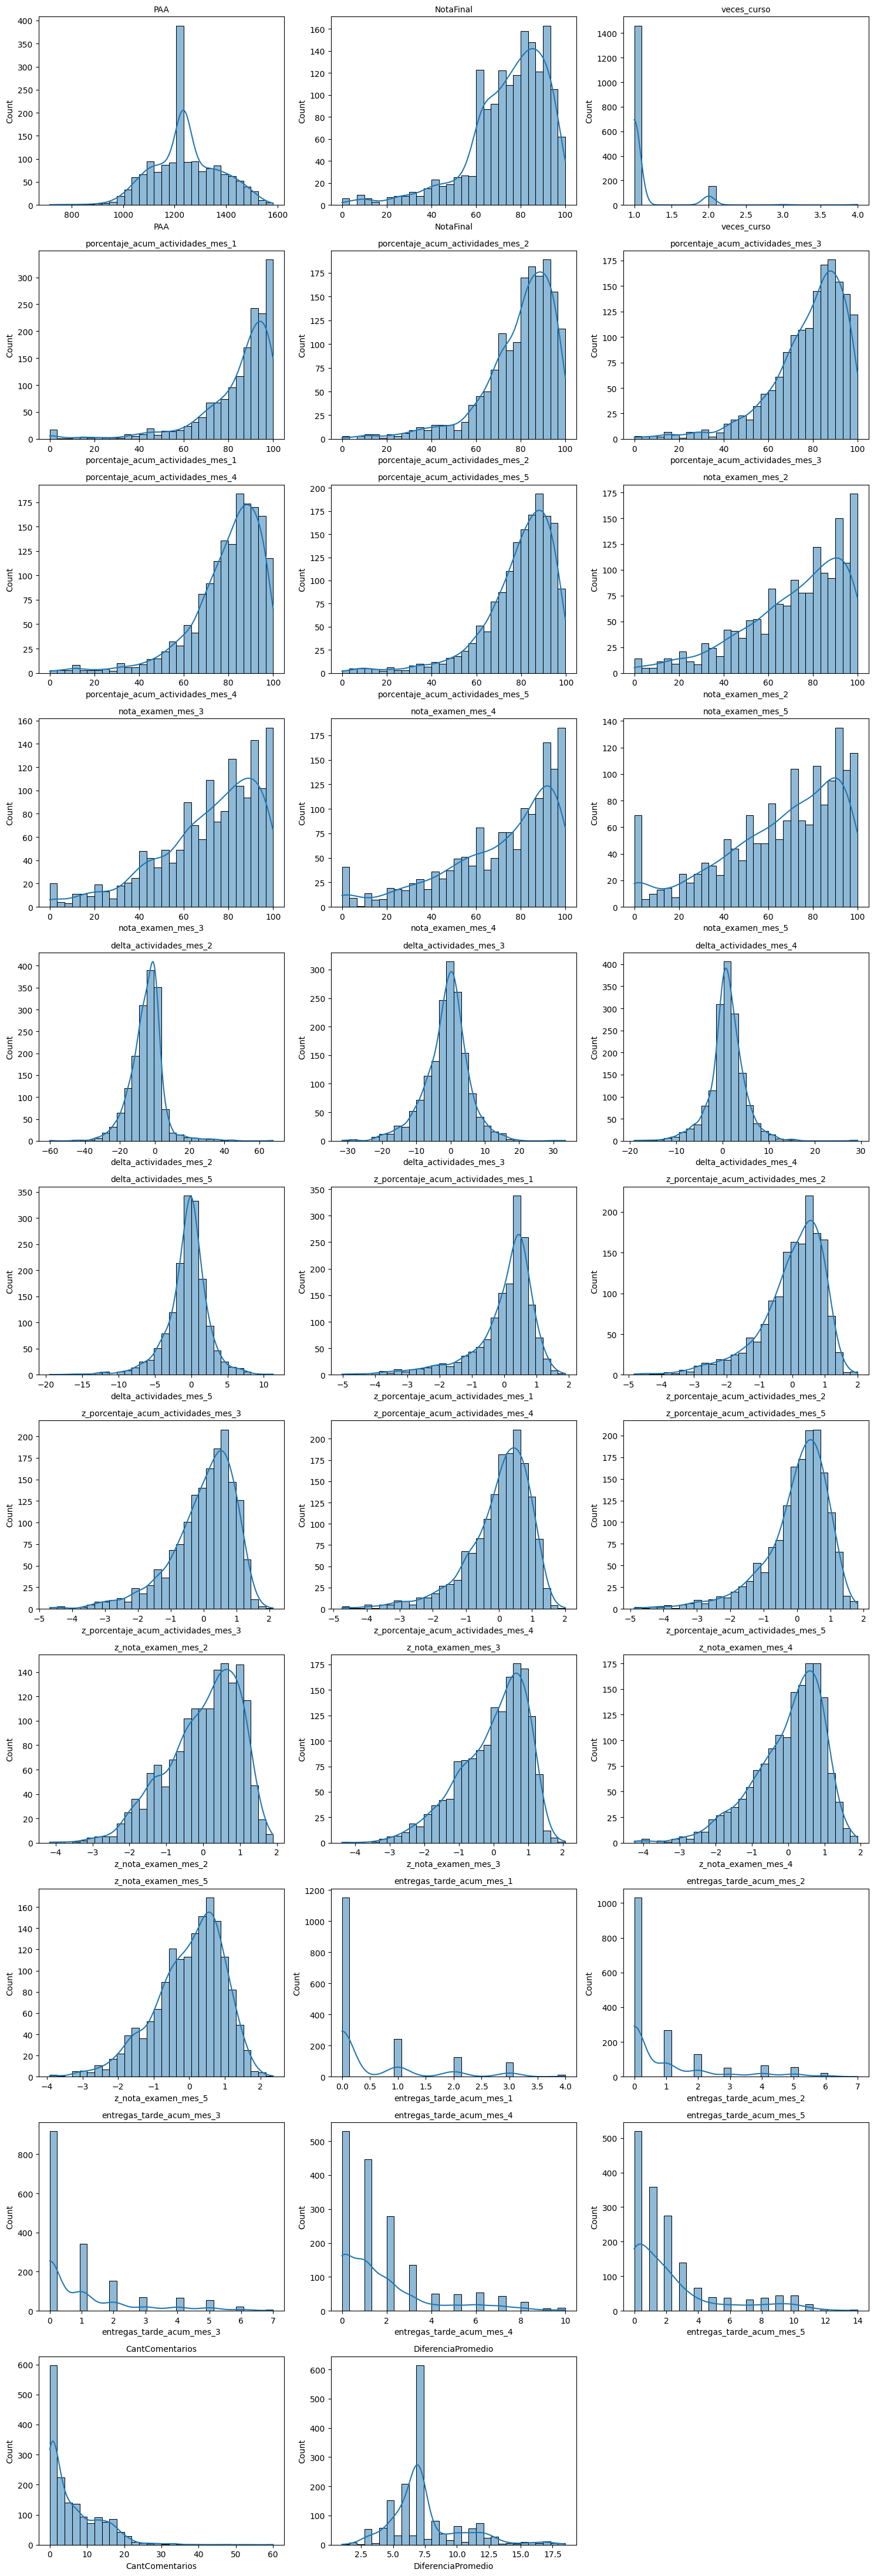

In [21]:
# Histograma de cada variable numérica
n_cols = 3
n_rows = int(np.ceil(len(variables) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
axes = axes.flatten()

for i, var in enumerate(variables):
    sns.histplot(data=datos, x=var, kde=True, ax=axes[i], bins=30)
    axes[i].set_title(var, fontsize=10)

for j in range(len(variables), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.savefig("figuras/histogramas_variables.png", dpi=200, bbox_inches="tight")
plt.show()

El análisis de distribución mostró detalles interesantes sobre el conjunto de datos.

Primero, observamos que el número de intentos del curso es significativamente diferente entre los estudiantes que reprueban y los que no. Por esa razón, vamos a analizar dicha variable de forma individual.

In [22]:
# Separación de aprobados y reprobados
aprobados = datos[datos['Aprobado'] == 1].copy()
reprobados = datos[datos['Aprobado'] == 0].copy() #Filtramos para reprobados y aprobados

In [23]:
# Intentos de los aprobados
aprobados['veces_curso'].value_counts()

veces_curso
1    1382
2      25
Name: count, dtype: int64

In [24]:
# Intentos de los reprobados
reprobados['veces_curso'].value_counts()

veces_curso
2    127
1     79
3      7
4      7
Name: count, dtype: int64

In [25]:
# Registros de los reprobados
reprobados

,Est_ID,PAA,Colegio,TituloNivelMedio,NotaFinal,Aprobado,Genero,EstadoCurso,veces_curso,Anio,...,z_porcentaje_acum_actividades_mes_3,z_porcentaje_acum_actividades_mes_4,z_porcentaje_acum_actividades_mes_5,z_nota_examen_mes_2,z_nota_examen_mes_3,z_nota_examen_mes_4,z_nota_examen_mes_5,CantComentarios,DiferenciaPromedio,Virtualidad
2297,1669.0,1278.0,CENTRO EDUCATIVO TECNICO LABORAL KINAL,OTRO,53.0,0,MASCULINO,REPROBADO,1,2019,...,-0.289500,-0.681716,-0.834518,-0.315888,-0.521216,-0.365376,-0.478099,0.0,7.0,0
2268,512.0,1050.0,COLEGIO BILINGUE MANOS A LA OBRA,BACHILLER EN CIENCIAS Y LETRAS,40.0,0,FEMENINO,REPROBADO,2,2020,...,-4.380329,-3.963240,-4.293739,-1.466745,-4.379130,-2.319231,-0.495216,2.0,7.0,1
1077,2029.0,1075.0,COLEGIO DESARROLLO DEL POTENCIAL INTELECTUAL V...,BACHILLER EN CIENCIAS Y LETRAS,53.0,0,FEMENINO,REPROBADO,2,2021,...,-0.975429,-0.838049,-0.806704,-0.415834,-0.916167,-1.204030,-1.013942,31.0,3.0,1
2271,580.0,1092.0,OTRO,BACHILLER EN CIENCIAS Y LETRAS CON ORIENTACION...,57.0,0,FEMENINO,REPROBADO,1,2019,...,-0.744344,-0.599171,-0.440075,-0.555839,-0.507687,-0.337131,-0.070985,1.0,7.0,0
2098,803.0,990.0,OTRO,BACHILLER EN CIENCIAS Y LETRAS CON ORIENTACION...,58.0,0,MASCULINO,REPROBADO,2,2022,...,-0.071074,-0.251053,-0.216825,-0.649823,-0.559862,-0.826376,-1.445350,7.0,7.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
220,166.0,1059.0,OTRO,BACHILLER EN CIENCIAS Y LETRAS,39.0,0,FEMENINO,REPROBADO,2,2019,...,-1.426258,-1.149102,-1.121059,-2.091708,-0.932022,-0.557684,-1.138386,1.0,7.0,0
685,912.0,1201.0,OTRO,DIPLOMA NIVEL MEDIO 3RO BASICO,48.0,0,MASCULINO,REPROBADO,1,2020,...,-0.221306,-0.223885,-0.899266,0.721269,-0.621433,-2.013004,-2.509861,1.0,8.0,1
1171,2550.0,1070.0,COLEGIO TECNOLOGICO AMERICANO AMERITEC,OTRO,57.0,0,MASCULINO,REPROBADO,2,2021,...,-2.084841,-1.848874,-1.968298,-1.463848,-2.328140,0.339700,-0.768787,11.0,6.5,1
561,1070.0,1041.0,OTRO,BACHILLER EN CIENCIAS Y LETRAS,15.0,0,MASCULINO,REPROBADO,2,2020,...,-4.235358,-4.566009,-4.672941,-3.230969,-3.191982,-4.015096,-2.597506,2.0,7.0,1


Observamos que, en el conjunto de entrenamiento, gran parte de los estudiantes que reprueban el curso no consigue mejorar su rendimiento en el segundo intento: solo 25 estudiantes aprobaron en su segundo intento, mientras que 127 reprobaron en él. Además, ningún estudiante con 3 o más intentos aprobó. Esto convierte a `veces_curso` en una de las variables más informativas.

## Análisis de variables categóricas

In [26]:
# Tablas de contingencia de las variables categóricas contra Aprobado
vars_categoricas = ['Virtualidad', 'Genero', 'Anio']

for var in vars_categoricas:
    tabla = pd.crosstab(datos[var], datos['Aprobado'])
    tabla.columns = ['Reprobado', 'Aprobado']
    print(f"\n=== {var} ===")
    print(tabla)
    print("\nProporción:")
    print(tabla.div(tabla.sum(axis=1), axis=0).round(3))


=== Virtualidad ===
             Reprobado  Aprobado
Virtualidad                     
0                  145       648
1                   75       759

Proporción:
             Reprobado  Aprobado
Virtualidad                     
0                0.183     0.817
1                0.090     0.910

=== Genero ===
           Reprobado  Aprobado
Genero                        
FEMENINO          63       530
MASCULINO        157       877

Proporción:
           Reprobado  Aprobado
Genero                        
FEMENINO       0.106     0.894
MASCULINO      0.152     0.848

=== Anio ===
      Reprobado  Aprobado
Anio                     
2019         70       292
2020         30       380
2021         45       379
2022         75       356

Proporción:
      Reprobado  Aprobado
Anio                     
2019      0.193     0.807
2020      0.073     0.927
2021      0.106     0.894
2022      0.174     0.826


Observamos que la tasa de reprobación **bajó** cuando el curso se impartió en modalidad virtual: 9.0 % en modalidad virtual frente a 18.3 % en presencial. Por año, 2020 (7.3 %) y 2021 (10.6 %) tienen las tasas más bajas, mientras que 2019 (19.3 %) y 2022 (17.4 %) tienen las más altas. En cuanto al género, la tasa de reprobación es de 15.2 % en hombres y de 10.6 % en mujeres.

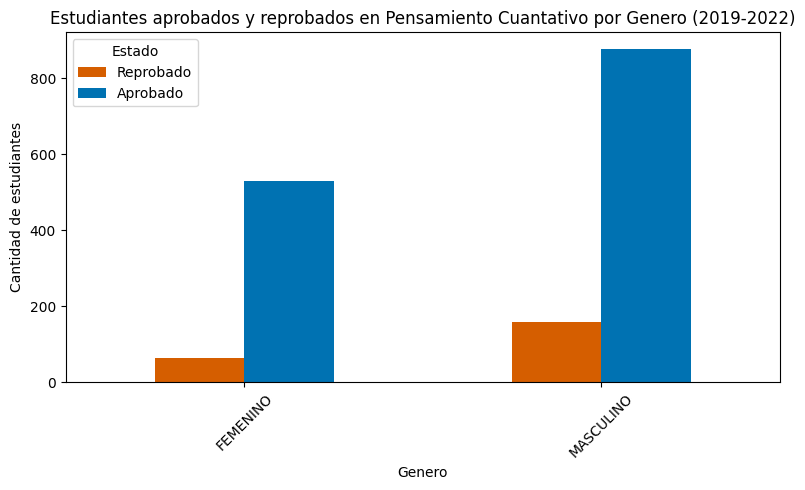

In [27]:
# Aprobados y reprobados por género
tabla = pd.crosstab(datos['Genero'], datos['Aprobado'])
tabla.columns = ['Reprobado', 'Aprobado']

fig, ax = plt.subplots(figsize=(8, 5))
tabla.plot(kind='bar', ax=ax, color=['#D55E00', '#0072B2'])
ax.set_title('Estudiantes aprobados y reprobados en Pensamiento Cuantativo por Genero (2019-2022)')
ax.set_xlabel('Genero')
ax.set_ylabel('Cantidad de estudiantes')
ax.legend(title='Estado')
ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig("figuras/aprobados_por_genero.png", dpi=200, bbox_inches="tight")
plt.show()

### Correlaciones
Usamos la correlación de **Spearman** (basada en rangos) porque captura relaciones monótonas aunque no sean lineales y es robusta a las distribuciones sesgadas y a los valores atípicos que observamos.

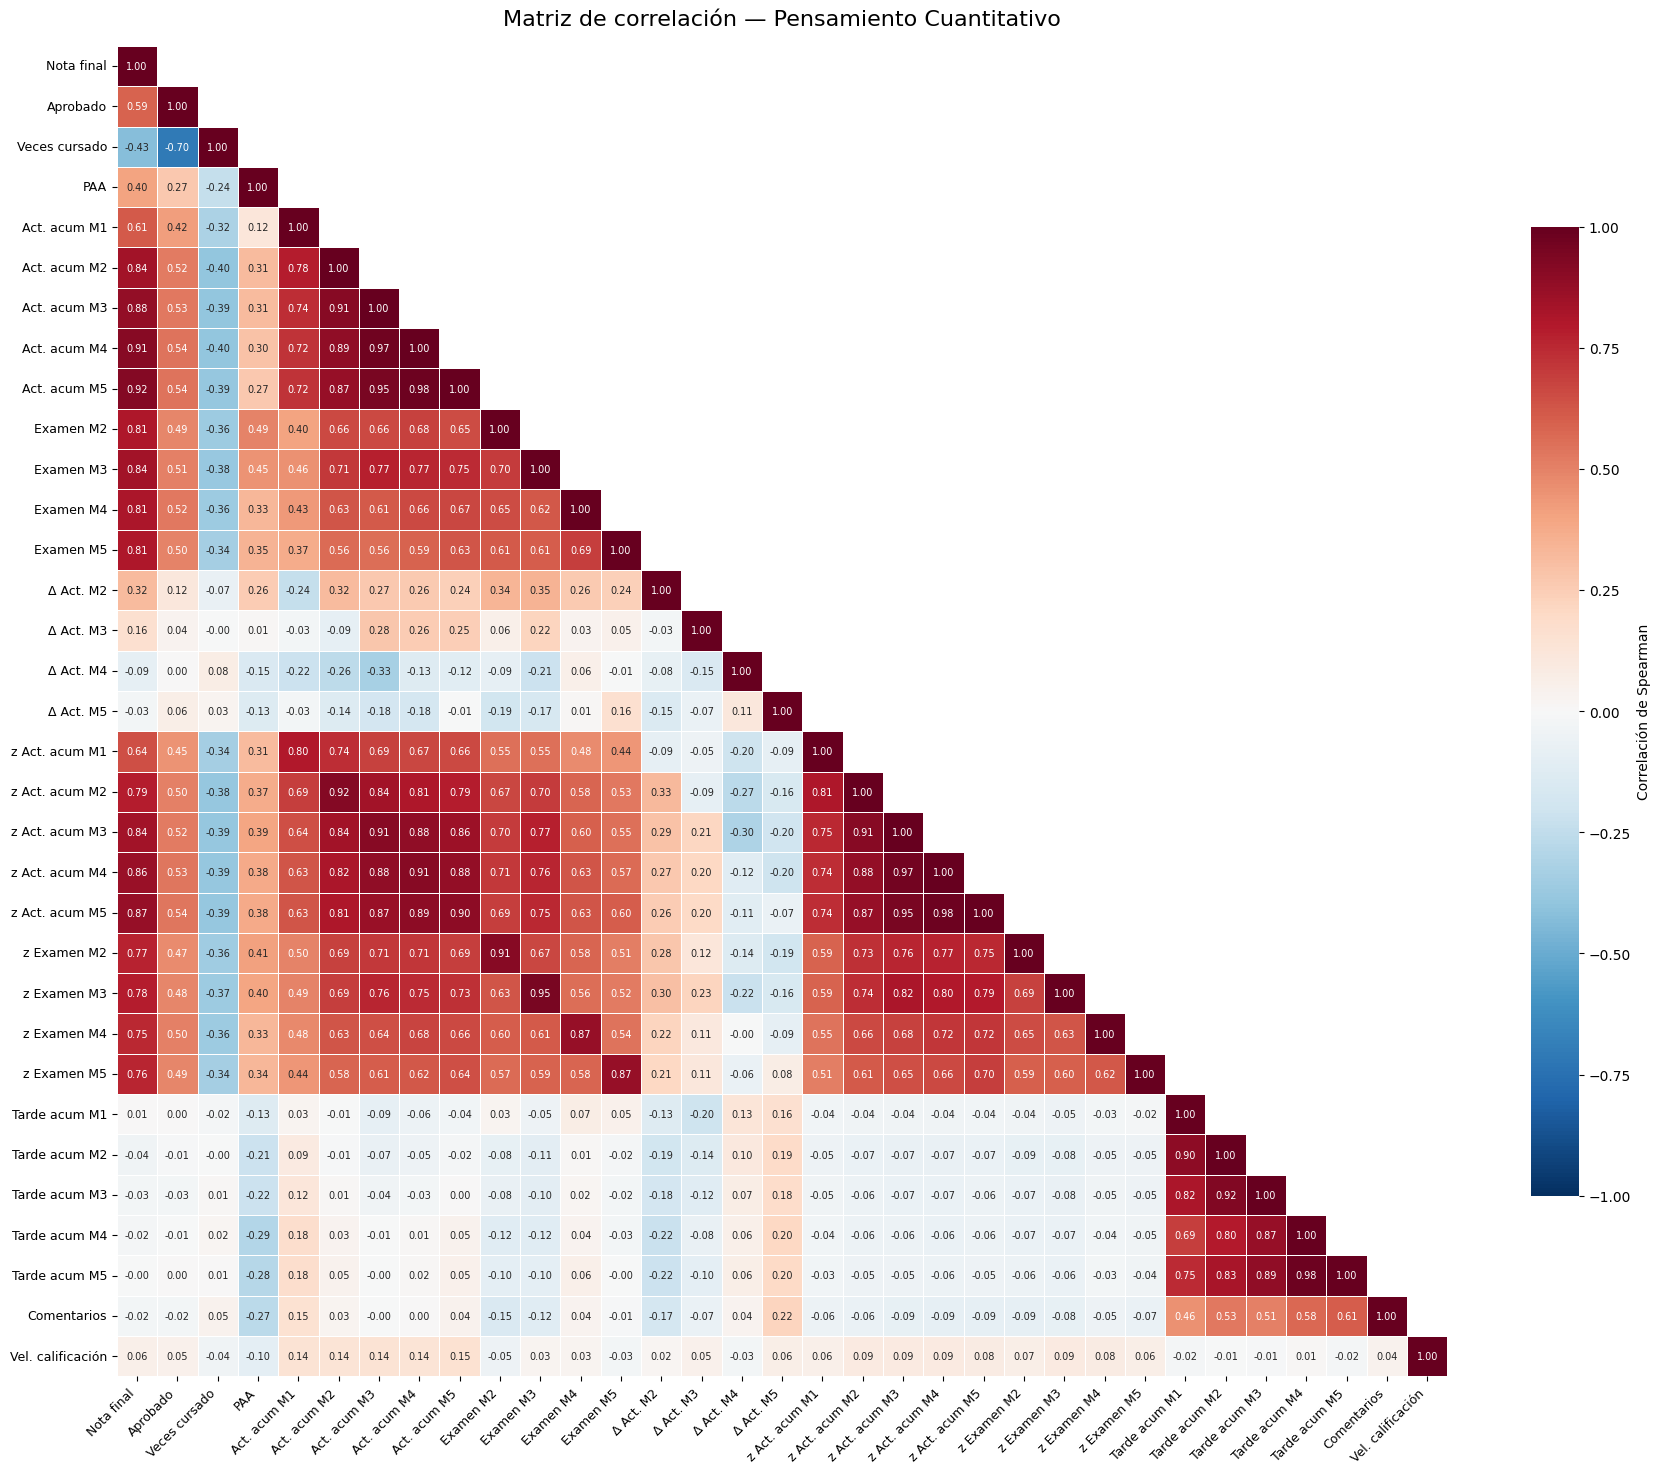

In [28]:
# Matriz de correlación de Spearman
cols = ['NotaFinal', 'Aprobado', 'veces_curso', 'PAA',
        'porcentaje_acum_actividades_mes_1', 'porcentaje_acum_actividades_mes_2',
        'porcentaje_acum_actividades_mes_3', 'porcentaje_acum_actividades_mes_4',
        'porcentaje_acum_actividades_mes_5',
        'nota_examen_mes_2', 'nota_examen_mes_3', 'nota_examen_mes_4', 'nota_examen_mes_5',
        'delta_actividades_mes_2', 'delta_actividades_mes_3',
        'delta_actividades_mes_4', 'delta_actividades_mes_5',
        'z_porcentaje_acum_actividades_mes_1', 'z_porcentaje_acum_actividades_mes_2',
        'z_porcentaje_acum_actividades_mes_3', 'z_porcentaje_acum_actividades_mes_4',
        'z_porcentaje_acum_actividades_mes_5',
        'z_nota_examen_mes_2', 'z_nota_examen_mes_3', 'z_nota_examen_mes_4', 'z_nota_examen_mes_5',
        'entregas_tarde_acum_mes_1', 'entregas_tarde_acum_mes_2', 'entregas_tarde_acum_mes_3',
        'entregas_tarde_acum_mes_4', 'entregas_tarde_acum_mes_5',
        'CantComentarios', 'DiferenciaPromedio']


def abreviar(c):
    """Abrevia los nombres de las variables para la matriz de correlación"""
    prefijos = {
        'z_porcentaje_acum_actividades_mes_': 'z Act. acum M',
        'porcentaje_acum_actividades_mes_':   'Act. acum M',
        'z_nota_examen_mes_':                 'z Examen M',
        'nota_examen_mes_':                   'Examen M',
        'delta_actividades_mes_':             'Δ Act. M',
        'entregas_tarde_acum_mes_':           'Tarde acum M',
    }
    for k, v in prefijos.items():
        if c.startswith(k):
            return v + c[len(k):]
    return {'NotaFinal': 'Nota final', 'veces_curso': 'Veces cursado',
            'CantComentarios': 'Comentarios', 'DiferenciaPromedio': 'Vel. calificación'}.get(c, c)

corr = datos[cols].corr(method='spearman').rename(index=abreviar, columns=abreviar)


# Solo se muestra el triángulo inferior
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(18, 15))
sns.heatmap(
    corr, mask=mask,
    cmap='RdBu_r', vmin=-1, vmax=1, center=0,
    annot=True, fmt='.2f', annot_kws={'size': 7},
    square=True, linewidths=0.5, linecolor='white',
    cbar_kws={'shrink': 0.7, 'label': 'Correlación de Spearman'},
    ax=ax
)
ax.set_title('Matriz de correlación — Pensamiento Cuantitativo', fontsize=16, pad=15)
ax.tick_params(axis='x', rotation=45, labelsize=9)
ax.tick_params(axis='y', rotation=0, labelsize=9)
plt.setp(ax.get_xticklabels(), ha='right')
plt.tight_layout()
plt.savefig("figuras/matriz_correlacion.png", dpi=200, bbox_inches="tight")
plt.show()

### Tamaño del efecto
Además del p-valor medimos el tamaño del efecto, porque con muestras grandes casi cualquier diferencia resulta significativa. Para las variables numéricas usamos la correlación biserial de rangos y para las categóricas la **V de Cramér** (basada en chi-cuadrado).

In [29]:
# Tamaño del efecto para variables numéricas
from scipy.stats import mannwhitneyu

def rank_biserial(df, var, objetivo='Aprobado'):
    """Calcula la correlación biserial de rangos y el p-valor de Mann-Whitney"""
    x1 = df.loc[df[objetivo] == 1, var].dropna()
    x0 = df.loc[df[objetivo] == 0, var].dropna()
    u, p = mannwhitneyu(x1, x0, alternative='two-sided')
    r = 2 * u / (len(x1) * len(x0)) - 1
    return r, p

In [30]:
# Asociación entre variables categóricas y Aprobado
def cramers_v_test(df, var, target='Aprobado'):
    """Aplica chi-cuadrado y calcula la V de Cramér entre una variable categórica y Aprobado"""
    tabla = pd.crosstab(df[var], df[target])
    chi2, p, dof, expected = chi2_contingency(tabla)
    n = tabla.sum().sum()
    v = (chi2 / (n * (min(tabla.shape) - 1))) ** 0.5
    return {'variable': var, 'chi2': chi2, 'p_value': p, 'cramers_v': v}

vars_categoricas = ['Genero', 'Colegio', 'TituloNivelMedio', 'Virtualidad']
resultados = pd.DataFrame([cramers_v_test(datos, v) for v in vars_categoricas])
resultados = resultados.sort_values('cramers_v', ascending=False)
print(resultados)

           variable        chi2       p_value  cramers_v
1           Colegio  150.848382  5.497223e-10   0.304492
3       Virtualidad   29.226136  6.440456e-08   0.134027
2  TituloNivelMedio   28.841373  2.502792e-02   0.133142
0            Genero    6.316714  1.196051e-02   0.062309


**Resultado (V de Cramér):** el colegio tiene la asociación más fuerte con aprobar (0.30), seguido de la virtualidad (0.13) y el título de nivel medio (0.13); el género tiene una asociación muy débil (0.06).

A continuación analizamos la relación de las variables categóricas con la **nota final** (variable continua): Mann-Whitney + biserial de rangos para la virtualidad (binaria) y Kruskal-Wallis + épsilon² para las demás.

In [ ]:
# Relación de las variables categóricas con la nota final


def rank_biserial(df, var, objetivo='Aprobado'):
    """Mann-Whitney entre los grupos 1 y 0 de `objetivo` para la variable `var`.
    Devuelve la correlación biserial de rangos (r) y el p-valor."""
    x1 = df.loc[df[objetivo] == 1, var].dropna()
    x0 = df.loc[df[objetivo] == 0, var].dropna()
    u, p = mannwhitneyu(x1, x0, alternative='two-sided')
    r = 2 * u / (len(x1) * len(x0)) - 1
    return r, p


def kruskal_test(df, var, objetivo='NotaFinal'):
    """Kruskal-Wallis de `objetivo` entre las categorías de `var`.
    Devuelve el estadístico H, el p-valor y el tamaño del efecto épsilon cuadrado."""
    datos = df[[var, objetivo]].dropna()
    grupos = [g[objetivo] for _, g in datos.groupby(var)]
    h, p = kruskal(*grupos)
    n, k = len(datos), len(grupos)
    epsilon2 = (h - k + 1) / (n - k)
    return {'variable': var, 'H': h, 'p_value': p, 'epsilon2': epsilon2}


def relacion_categoricas_notafinal(df, objetivo='NotaFinal'):
    """Compara la nota final entre las categorías de cada variable categórica"""
    filas = []

    # Virtualidad: binaria -> Mann-Whitney + biserial de rangos
    r, p = rank_biserial(df, objetivo, objetivo='Virtualidad')
    filas.append({'variable': 'Virtualidad', 'prueba': 'Mann-Whitney',
                  'p_value': p, 'efecto': r, 'medida': 'Biserial de rangos'})

    # Más de dos categorías -> Kruskal-Wallis + épsilon cuadrado
    for var in ['Colegio', 'TituloNivelMedio', 'Genero']:
        res = kruskal_test(df, var, objetivo=objetivo)
        filas.append({'variable': var, 'prueba': 'Kruskal-Wallis',
                      'p_value': res['p_value'], 'efecto': res['epsilon2'],
                      'medida': 'Épsilon cuadrado'})

    tabla = pd.DataFrame(filas)
    tabla['significativa'] = tabla['p_value'] < 0.05
    return tabla


resultados = relacion_categoricas_notafinal(train)
print(resultados.round(4))

           variable          prueba  p_value  efecto              medida  \
0       Virtualidad    Mann-Whitney   0.0000  0.2027  Biserial de rangos   
1           Colegio  Kruskal-Wallis   0.0000  0.0995    Épsilon cuadrado   
2  TituloNivelMedio  Kruskal-Wallis   0.0020  0.0132    Épsilon cuadrado   
3            Genero  Kruskal-Wallis   0.0415  0.0019    Épsilon cuadrado   

   significativa  
0           True  
1           True  
2           True  
3           True  


**Resultado:** todas son significativas, pero los efectos son pequeños: virtualidad r = 0.20, colegio ε² = 0.10, título ε² = 0.01 y género ε² = 0.002 (prácticamente nulo).

In [32]:
# Nota final según modalidad
resultado = pd.DataFrame([
    prueba_mann_whitney(train, "NotaFinal",
                        nombres={"NotaFinal": "Nota final según modalidad"},
                        col_objetivo="Virtualidad")
])
print(resultado)

                     Variable       p_valor             sig  Valor esperado
0  Nota final según modalidad  1.456169e-12  Paso la prueba            0.05


Comparamos la nota final según el género y según la modalidad del curso.

In [33]:
# Género como variable binaria
train["Genero_bin"] = train["Genero"].map({"MASCULINO": 0, "FEMENINO": 1})

In [34]:
# Nota final según género
resultado = pd.DataFrame([
    prueba_mann_whitney(train, "NotaFinal",
                        nombres={"NotaFinal": "Nota final según género"},
                        col_objetivo="Genero_bin")
])
print(resultado)

                  Variable   p_valor             sig  Valor esperado
0  Nota final según género  0.041549  Paso la prueba            0.05


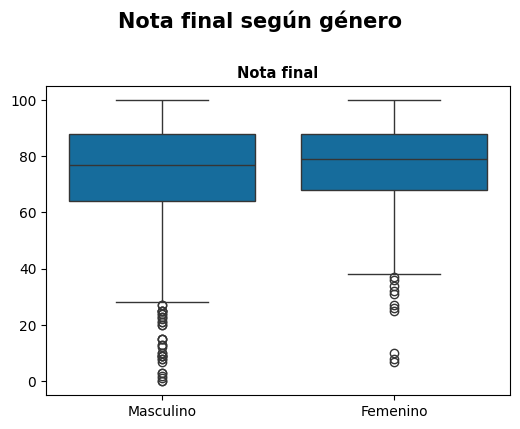

In [35]:
# Boxplot de la nota final según género
graficar_boxplots(train, ["NotaFinal"], "Nota final según género",
                  nombres={"NotaFinal": "Nota final"},
                  col_objetivo="Genero_bin",
                  etiquetas=("Masculino", "Femenino"),
                  archivo="figuras/boxplot_notafinal_genero.png");

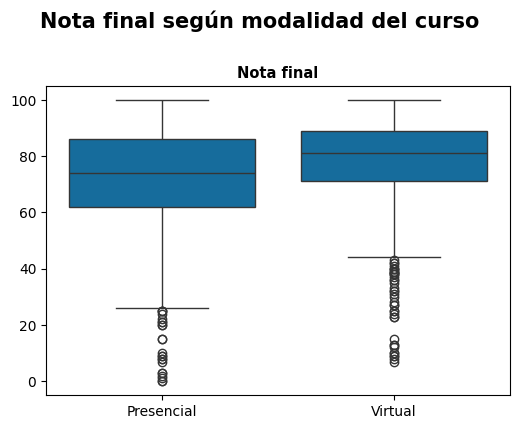

In [36]:
# Boxplot de la nota final según modalidad
graficar_boxplots(train, ["NotaFinal"], "Nota final según modalidad del curso",
                  nombres={"NotaFinal": "Nota final"},
                  col_objetivo="Virtualidad",
                  etiquetas=("Presencial", "Virtual"),
                  archivo="figuras/boxplot_notafinal_virtualidad.png");

## Multicolinealidad (VIF)
Calculamos el factor de inflación de la varianza (VIF) del conjunto de variables que tendría cada modelo mensual. Un VIF mayor a 5 indica que la variable es redundante con las demás. Probamos tres configuraciones:

1. **Todas las variables** (incluyendo puntuaciones z): las puntuaciones z y sus variables originales tienen VIF entre 6 y 14, porque el z-score es casi una transformación lineal del mismo valor dentro de cada sección.
2. **Sin puntuaciones z:** todos los VIF bajan a menos de 3.5.
3. **Sin puntuaciones z ni notas de parciales:** todos los VIF quedan por debajo de 1.5.

In [37]:
# VIF con todas las variables de cada modelo mensual
def vif(df, cols):
    """Calcula el VIF de cada variable"""
    X = sm.add_constant(df[cols].dropna())
    return (pd.DataFrame({
        'variable': cols,
        'VIF': [variance_inflation_factor(X.values, i + 1) for i in range(len(cols))],
    }).sort_values('VIF', ascending=False))

base = ['PAA', 'veces_curso', 'DiferenciaPromedio']

for i in range(1, 5):
    cols = base + [f'porcentaje_acum_actividades_mes_{i}']
    if i >= 2:
        cols += [f'nota_examen_mes_{j}' for j in range(2, i + 1)]
        cols += [f'delta_actividades_mes_{i}']
        cols += [f'z_nota_examen_mes_{i}'] 
        cols += [f'z_porcentaje_acum_actividades_mes_{i}']   
    print(f"\n--- Mes {i} ---")
    print(vif(datos, cols).round(2))


--- Mes 1 ---
                            variable   VIF
1                        veces_curso  1.22
3  porcentaje_acum_actividades_mes_1  1.19
0                                PAA  1.10
2                 DiferenciaPromedio  1.03

--- Mes 2 ---
                              variable   VIF
7  z_porcentaje_acum_actividades_mes_2  7.06
3    porcentaje_acum_actividades_mes_2  6.56
4                    nota_examen_mes_2  6.42
6                  z_nota_examen_mes_2  6.35
0                                  PAA  1.38
1                          veces_curso  1.31
5              delta_actividades_mes_2  1.10
2                   DiferenciaPromedio  1.08

--- Mes 3 ---
                              variable    VIF
5                    nota_examen_mes_3  13.80
7                  z_nota_examen_mes_3  12.69
8  z_porcentaje_acum_actividades_mes_3   9.36
3    porcentaje_acum_actividades_mes_3   7.68
4                    nota_examen_mes_2   2.84
0                                  PAA   1.41
1            

**Configuración 2:** sin puntuaciones z.

In [38]:
# VIF sin puntuaciones z
for i in range(1, 5):
    cols = base + [f'porcentaje_acum_actividades_mes_{i}']
    if i >= 2:
        cols += [f'nota_examen_mes_{j}' for j in range(2, i + 1)]
        cols += [f'delta_actividades_mes_{i}']
        # cols += [f'z_nota_examen_mes_{i}'] 
        # cols += [f'z_porcentaje_acum_actividades_mes_{i}']   
    print(f"\n--- Mes {i} ---")
    print(vif(datos, cols).round(2))


--- Mes 1 ---
                            variable   VIF
1                        veces_curso  1.22
3  porcentaje_acum_actividades_mes_1  1.19
0                                PAA  1.10
2                 DiferenciaPromedio  1.03

--- Mes 2 ---
                            variable   VIF
4                  nota_examen_mes_2  2.17
3  porcentaje_acum_actividades_mes_2  1.90
0                                PAA  1.35
1                        veces_curso  1.30
5            delta_actividades_mes_2  1.10
2                 DiferenciaPromedio  1.05

--- Mes 3 ---
                            variable   VIF
5                  nota_examen_mes_3  3.30
3  porcentaje_acum_actividades_mes_3  2.74
4                  nota_examen_mes_2  2.51
0                                PAA  1.39
1                        veces_curso  1.32
6            delta_actividades_mes_3  1.14
2                 DiferenciaPromedio  1.05

--- Mes 4 ---
                            variable   VIF
5                  nota_examen_mes_3 

**Configuración 3:** sin puntuaciones z ni notas de parciales.

In [39]:
# VIF sin puntuaciones z ni notas de parciales
for i in range(1, 5):
    cols = base + [f'porcentaje_acum_actividades_mes_{i}']
    if i >= 2:
        # cols += [f'nota_examen_mes_{j}' for j in range(2, i + 1)]
        cols += [f'delta_actividades_mes_{i}']
        # cols += [f'z_nota_examen_mes_{i}'] 
        # cols += [f'z_porcentaje_acum_actividades_mes_{i}']   
    print(f"\n--- Mes {i} ---")
    print(vif(datos, cols).round(2))


--- Mes 1 ---
                            variable   VIF
1                        veces_curso  1.22
3  porcentaje_acum_actividades_mes_1  1.19
0                                PAA  1.10
2                 DiferenciaPromedio  1.03

--- Mes 2 ---
                            variable   VIF
3  porcentaje_acum_actividades_mes_2  1.37
1                        veces_curso  1.28
0                                PAA  1.18
4            delta_actividades_mes_2  1.05
2                 DiferenciaPromedio  1.04

--- Mes 3 ---
                            variable   VIF
3  porcentaje_acum_actividades_mes_3  1.45
1                        veces_curso  1.28
0                                PAA  1.16
4            delta_actividades_mes_3  1.09
2                 DiferenciaPromedio  1.04

--- Mes 4 ---
                            variable   VIF
3  porcentaje_acum_actividades_mes_4  1.32
1                        veces_curso  1.26
0                                PAA  1.16
2                 DiferenciaPromedio 

**Decisión:** no usar las puntuaciones z en los modelos. Las notas de parciales sí se conservan, porque sin los z-scores su VIF es aceptable (< 3.5) y son de las variables más relacionadas con el resultado.

Finalmente, la distribución de la nota final según el número de intentos.

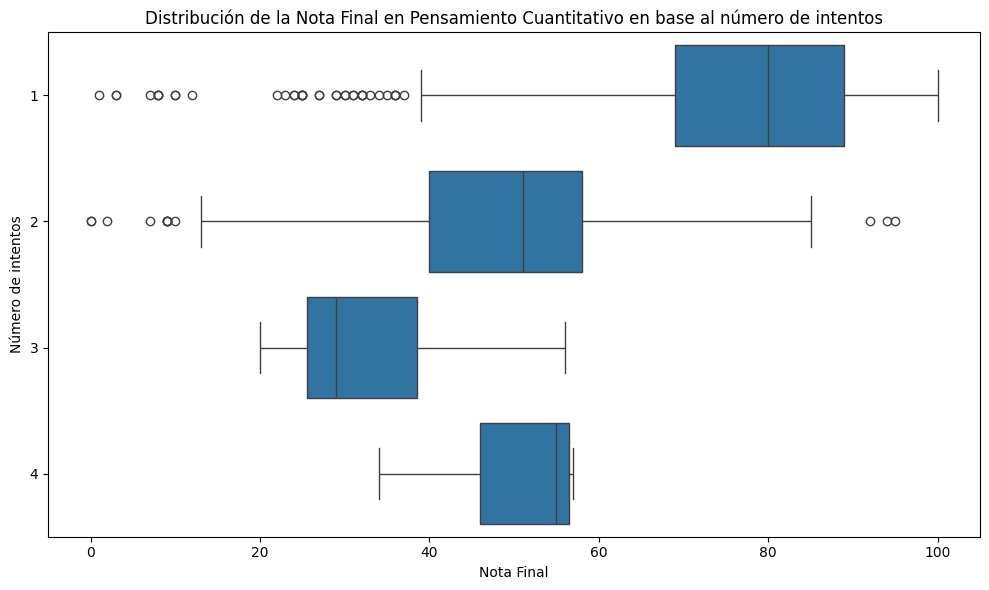

In [40]:
# Nota final según el número de intentos
fig, ax = plt.subplots(figsize=(10, 6))

sns.boxplot(
    data=datos,
    x='NotaFinal',
    y='veces_curso',
    orient='h',
    order=sorted(datos['veces_curso'].dropna().unique()),
    ax=ax
)

ax.set_title('Distribución de la Nota Final en Pensamiento Cuantitativo en base al número de intentos')
ax.set_xlabel('Nota Final')
ax.set_ylabel('Número de intentos')

plt.tight_layout()
plt.savefig("figuras/boxplot_notafinal_intentos.png", dpi=200, bbox_inches="tight")
plt.show()